In [62]:
from sklearn import svm
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.inspection import DecisionBoundaryDisplay
from seaborn import heatmap
import matplotlib.pyplot as plt
import pandas as pd

In [63]:
df = pd.read_csv("heart+disease/processed.cleveland.data",header=None)
df = df.replace("?",None)

# preprocessing

df.columns = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","num"]
df["ca"] = df["ca"].astype("float64")
df["thal"] = df["thal"].astype("float64")
df["ca"] = df["ca"].fillna(df["ca"].median())
df["thal"] = df["thal"].fillna(df["thal"].median())
df["num"] = df["num"].replace(2,1)
df["num"] = df["num"].replace(3,1)
df["num"] = df["num"].replace(4,1)


In [64]:
x = df[["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal"]]
y = df["num"]

x_train, x_test, y_train, y_test = train_test_split(x,y,train_size=0.8,random_state=42)

0.8852459016393442


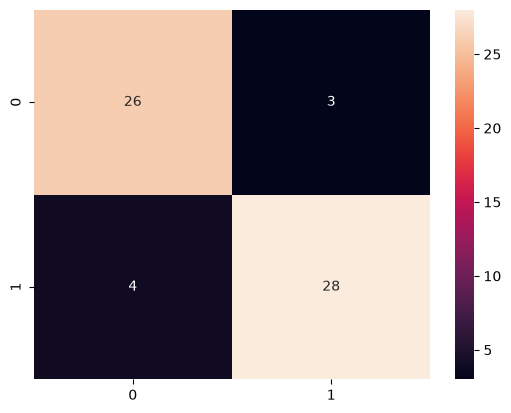

In [65]:
svc = svm.SVC(kernel="linear")
svc.fit(x_train,y_train)
y_pred = svc.predict(x_test)

print(accuracy_score(y_test,y_pred))
heatmap(confusion_matrix(y_test,y_pred),annot=True)

plt.show()

In [66]:
y.value_counts()

num
0    164
1    139
Name: count, dtype: int64

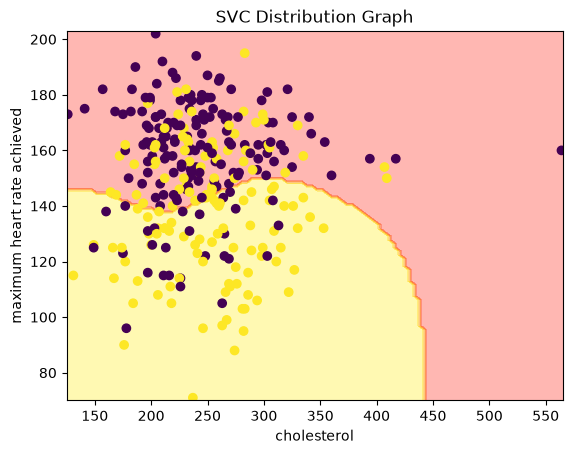

In [67]:
svc = svm.SVC(kernel="rbf")
x = x[["chol","thalach"]]
svc.fit(x,y)

DecisionBoundaryDisplay.from_estimator(svc,x,response_method="predict",cmap=plt.cm.autumn,alpha=0.3)
plt.title("SVC Distribution Graph")
plt.xlabel("cholesterol")
plt.ylabel("maximum heart rate achieved")
plt.scatter(x=x["chol"],y=x["thalach"],c=y)

plt.show()